# Analisi linee murine (D2A1, D2.0R) — unità = cellula

Ogni **sottocartella** della cartella di una giornata è una **cellula**.
- **Forza-indentazione**: ogni curva della cellula (di solito 3) è fittata con Ting; la cellula è rappresentata dalla media delle sue curve.
- **Stress-relaxation**: le curve della cellula sono mediate in una curva della cellula, che viene poi fittata (SLS, PLR, bi-exp, poroelastico).

Alla fine: tabella per cellula, curva SR media di ciascuna linea, test di Mann–Whitney tra le due linee (una osservazione per cellula).

**Da modificare:** solo la cella 2 (cartelle delle due linee).

**Nota:** gli output già salvati precedono la rampa di chiusura al contatto e i nuovi criteri di esclusione. Rieseguire la cella di analisi completa per aggiornare i risultati in `aggregated/per_cellula_murine_chiusura_contatto`.

In [25]:
# 1. Import
import sys
sys.path.insert(0, r'/Users/furbetta/Desktop/PyFMlab_DyNaMo/PyFMGUI_DyNaMo')
sys.path.insert(0, r'/Users/furbetta/Desktop/PyFMlab_DyNaMo/PyFMGUI_DyNaMo/general/src')

import importlib
import warnings
import matplotlib.pyplot as plt
import analisi_per_cellula as apc
importlib.reload(apc)

warnings.filterwarnings("ignore")
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

sr_utils: uso il file /Users/furbetta/Desktop/PyFMlab_DyNaMo/PyFMGUI_DyNaMo/sr_utils.py


In [26]:
# 2. Configurazione
SISTEMA = "murine"

# Per ogni linea: le cartelle delle giornate. Dentro ciascuna: <cellula>/FD e <cellula>/SR
LINEE = {
    "D2A1": [
        r"/Users/furbetta/Desktop/PyFMlab_DyNaMo/PyFMGUI_DyNaMo/140326/A1",
        r"/Users/furbetta/Desktop/PyFMlab_DyNaMo/PyFMGUI_DyNaMo/240326/A1",
        r"/Users/furbetta/Desktop/PyFMlab_DyNaMo/PyFMGUI_DyNaMo/270326/A1",
        r"/Users/furbetta/Desktop/PyFMlab_DyNaMo/PyFMGUI_DyNaMo/100426/A1/SAMPLE1",
        r"/Users/furbetta/Desktop/PyFMlab_DyNaMo/PyFMGUI_DyNaMo/100426/A1/SAMPLE2",
        # aggiungi qui le altre giornate D2A1
    ],
    "D2.0R": [
        r"/Users/furbetta/Desktop/PyFMlab_DyNaMo/PyFMGUI_DyNaMo/160426/0R",
        r"/Users/furbetta/Desktop/PyFMlab_DyNaMo/PyFMGUI_DyNaMo/140326/0R",
        r"/Users/furbetta/Desktop/PyFMlab_DyNaMo/PyFMGUI_DyNaMo/240326/0R",
        r"/Users/furbetta/Desktop/PyFMlab_DyNaMo/PyFMGUI_DyNaMo/150426/0R/SAMPLE1",
        r"/Users/furbetta/Desktop/PyFMlab_DyNaMo/PyFMGUI_DyNaMo/150426/0R/SAMPLE2",
        # aggiungi qui le altre giornate D2.0R
    ],
}

OUTPUT_DIR = r"/Users/furbetta/Desktop/PyFMlab_DyNaMo/PyFMGUI_DyNaMo/aggregated/per_cellula_murine_chiusura_contatto"
ESEGUI_FD = True
ESEGUI_SR = True
OPZIONI_TING = {"param_overrides": {"apply_ramp_correction": True}}

# Criteri di esclusione (gli stessi per le due linee). Per non escludere nulla: CRITERI = None
# fd_r2_min: R2 minimo del fit di Ting; fd_max_rapporto_hertz_E0: E_Hertz/E0 tra 1/3 e 3;
# sr_F_relax_fisico: 0 < F_relax <= 1; sr_r2_min: R2 minimo del miglior modello della fase tardiva
CRITERI = dict(apc.CRITERI_MURINE)
CRITERI["sr_F_relax_fisico"] = False
ALTEZZE_UM = {"D2A1": 4.6, "D2.0R": 4.6}

In [27]:
# 3. Controllo: quali cellule vengono trovate (nessun fit)
cells = apc.find_cells(LINEE, SISTEMA)
apc.print_cells_overview(cells)
display(cells[["linea", "giornata", "cartella", "tipo", "id_cellula", "n_curve"]].head(20))

Cellule trovate:


,linea,tipo,giornate,cellule,curve
0,D2.0R,FD,5,51,158
1,D2.0R,SR,5,51,178
2,D2A1,FD,5,50,155
3,D2A1,SR,5,49,186


,linea,giornata,cartella,tipo,id_cellula,n_curve
0,D2A1,140326/A1,cell01,FD,140326/A1/cell01,3
1,D2A1,140326/A1,cell01,SR,140326/A1/cell01,5
2,D2A1,140326/A1,cell04,FD,140326/A1/cell04,3
3,D2A1,140326/A1,cell04,SR,140326/A1/cell04,4
4,D2A1,140326/A1,cell05,FD,140326/A1/cell05,3
5,D2A1,140326/A1,cell05,SR,140326/A1/cell05,3
6,D2A1,140326/A1,cell06,FD,140326/A1/cell06,3
7,D2A1,140326/A1,cell06,SR,140326/A1/cell06,3
8,D2A1,140326/A1,cell07,FD,140326/A1/cell07,3
9,D2A1,140326/A1,cell07,SR,140326/A1/cell07,3


Cellule trovate:


,linea,tipo,giornate,cellule,curve
0,D2.0R,FD,5,51,158
1,D2.0R,SR,5,51,178
2,D2A1,FD,5,50,155
3,D2A1,SR,5,49,186



=== Curve forza-indentazione ===
ting_utils: uso il file /Users/furbetta/Desktop/PyFMlab_DyNaMo/PyFMGUI_DyNaMo/ting_utils.py
[FD 1/313] 140326/A1/cell01 - cell1_FD-0000.jpk-force
[FD 2/313] 140326/A1/cell01 - cell1_FD-0001.jpk-force
[FD 3/313] 140326/A1/cell01 - cell1_FD-0002.jpk-force
[FD 4/313] 140326/A1/cell04 - cell4_FD-0000.jpk-force
[FD 5/313] 140326/A1/cell04 - cell4_FD-0001.jpk-force
[FD 6/313] 140326/A1/cell04 - cell4_FD-0002.jpk-force
[FD 7/313] 140326/A1/cell05 - cell5_FD-0000.jpk-force
[FD 8/313] 140326/A1/cell05 - cell5_FD-0001.jpk-force
[FD 9/313] 140326/A1/cell05 - cell5_FD-0002.jpk-force
[FD 10/313] 140326/A1/cell06 - cell6_FD-0000.jpk-force
[FD 11/313] 140326/A1/cell06 - cell6_FD-0001.jpk-force
[FD 12/313] 140326/A1/cell06 - cell6_FD-0002.jpk-force
[FD 13/313] 140326/A1/cell07 - cell7_FD-0000.jpk-force
[FD 14/313] 140326/A1/cell07 - cell7_FD-0001.jpk-force
[FD 15/313] 140326/A1/cell07 - cell7_FD-0002.jpk-force
[FD 16/313] 140326/A1/cell08 - cell8_FD-0000.jpk-force
[FD

[TingFit] Warning: Hertz delta0=724860.6nm diverged (z_range=8201.3nm). Using RoV PoC only (delta0=0).
[TingFit] Warning: Hertz delta0=724865.3nm diverged (z_range=8201.3nm). Using RoV PoC only (delta0=0).


[FD 21/313] 140326/A1/cell09 - cell9_FD-0002.jpk-force
[FD 22/313] 140326/A1/cell10 - cell10_FD-0000.jpk-force


...

[FD 277/313] 0R/SAMPLE1/cell09 - cell09_FD-0006.jpk-force
[FD 278/313] 0R/SAMPLE1/cell10 - cell10_FD-0000.jpk-force
[FD 279/313] 0R/SAMPLE1/cell10 - cell10_FD-0001.jpk-force
[FD 280/313] 0R/SAMPLE1/cell10 - cell10_FD-0002.jpk-force
[FD 281/313] 0R/SAMPLE2/cell01 - cell12_FD-2026.04.15-15.20.53.434.jpk-force
[FD 282/313] 0R/SAMPLE2/cell01 - cell12_FD-2026.04.15-15.21.16.294.jpk-force
[FD 283/313] 0R/SAMPLE2/cell01 - cell12_FD-2026.04.15-15.21.29.143.jpk-force


[TingFit] Warning: Hertz delta0=713024.2nm diverged (z_range=8088.7nm). Using RoV PoC only (delta0=0).


[FD 284/313] 0R/SAMPLE2/cell03 - cell3_FD-0000.jpk-force
[FD 285/313] 0R/SAMPLE2/cell03 - cell3_FD-0001.jpk-force
[FD 286/313] 0R/SAMPLE2/cell03 - cell3_FD-0002.jpk-force
[FD 287/313] 0R/SAMPLE2/cell03 - cell3_FD-0003.jpk-force
[FD 288/313] 0R/SAMPLE2/cell04 - cell4_FD-0000.jpk-force


[TingFit] Warning: Hertz delta0=712914.6nm diverged (z_range=7292.8nm). Using RoV PoC only (delta0=0).


[FD 289/313] 0R/SAMPLE2/cell04 - cell4_FD-0001.jpk-force
[FD 290/313] 0R/SAMPLE2/cell04 - cell4_FD-0002.jpk-force
[FD 291/313] 0R/SAMPLE2/cell04 - cell4_FD-0003.jpk-force
[FD 292/313] 0R/SAMPLE2/cell05 - cell5_FD-0000.jpk-force
[FD 293/313] 0R/SAMPLE2/cell05 - cell5_FD-0001.jpk-force
[FD 294/313] 0R/SAMPLE2/cell05 - cell5_FD-0002.jpk-force
[FD 295/313] 0R/SAMPLE2/cell05 - cell5_FD-0003.jpk-force
[FD 296/313] 0R/SAMPLE2/cell07 - cell7_FD-0003.jpk-force
[FD 297/313] 0R/SAMPLE2/cell07 - cell7_FD-0004.jpk-force
[FD 298/313] 0R/SAMPLE2/cell07 - cell7_FD-0005.jpk-force
[FD 299/313] 0R/SAMPLE2/cell08 - cell8_FD-0000.jpk-force
[FD 300/313] 0R/SAMPLE2/cell08 - cell8_FD-0001.jpk-force
[FD 301/313] 0R/SAMPLE2/cell08 - cell8_FD-0002.jpk-force
[FD 302/313] 0R/SAMPLE2/cell09 - cell9_FD-0000.jpk-force
[FD 303/313] 0R/SAMPLE2/cell09 - cell9_FD-0001.jpk-force
[FD 304/313] 0R/SAMPLE2/cell09 - cell9_FD-0002.jpk-force
[FD 305/313] 0R/SAMPLE2/cell10 - cell10_FD-0000.jpk-force
[FD 306/313] 0R/SAMPLE2/cell10

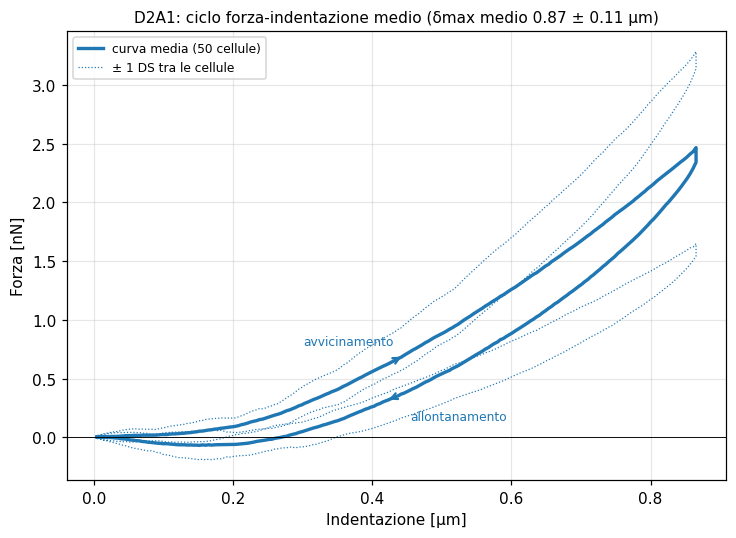

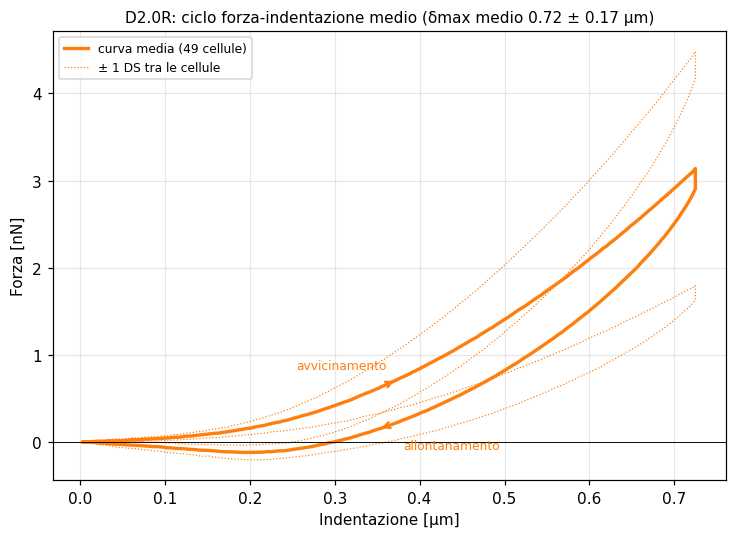

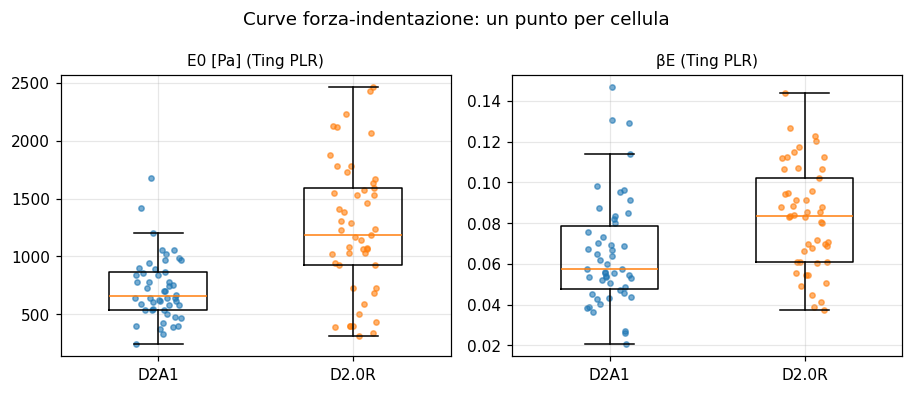


=== Curve di stress-relaxation ===
[SR 1/100] 140326/A1/cell01 (5 curve)


,confronto,modello,parametri,RMSE_finestra,R2_finestra,AICc_finestra,dAICc_finestra
0,finestra_iniziale,Poroelastico,"F∞=0.6491, τp=0.2599 s",0.00604,0.99362,-7607.91459,1400.82147
1,finestra_iniziale,SLS,"F∞=0.7635, τ=0.0654 s",0.01897,0.93716,-5903.77730,3104.95875
2,finestra_iniziale,PLR (1+t/t0)^-b,"t0=0.009301 s, β=0.0747",0.00314,0.99828,-8585.05254,423.68351
3,finestra_iniziale,Bi-exp GM,"F∞=0.7155, w=0.3440, τ1=0.0159 s, τ2=0.2343 s",0.00235,0.99903,-9008.73605,0.00000
4,intera_curva_da_0,SLS,"F∞=0.6681, τ=0.1652 s",0.03851,0.74103,NaN,NaN
5,intera_curva_da_0,PLR (1+t/t0)^-b,"t0=0.009042 s, β=0.0746",0.00334,0.99805,NaN,NaN
6,intera_curva_da_0,Bi-exp GM,"F∞=0.6313, w=0.4100, τ1=0.0297 s, τ2=0.7770 s",0.00734,0.99058,NaN,NaN


,candidate_t_s,late_model,late_r2,score
19,0.67750,bi,0.970561,0.003525
1,0.27375,plr,0.974299,0.010523


,dominio,modello,parametri,R2
0,early-phase (0-0.677s),Poroelastico,"F∞=0.6478, τp=0.2636 s",0.9944
1,post-transizione (t≥0.677s),Bi-exp GM,"F∞=0.6127, w=0.7360, τ1=0.2931 s, τ2=2.6375 s",0.9706
2,post-transizione (t≥0.677s),PLR puro,"t0=0.0018 s, β=0.0583",0.9605
3,post-transizione (t≥0.677s),SLS,"F∞=0.6342, τ=0.5541 s",0.8109


[SR 2/100] 140326/A1/cell04 (4 curve)


...

,candidate_t_s,late_model,late_r2,score
14,0.55875,bi,0.998456,0.003318
0,0.25000,plr,0.999791,0.000849


,dominio,modello,parametri,R2
0,early-phase (0-0.250s),Poroelastico,"F∞=0.6761, τp=0.1195 s",0.9961
1,post-transizione (t≥0.250s),PLR puro,"t0=0.0062 s, β=0.0770",0.9998
2,post-transizione (t≥0.250s),Bi-exp GM,"F∞=0.5730, w=0.6329, τ1=0.1426 s, τ2=2.4680 s",0.9963
3,post-transizione (t≥0.250s),SLS,"F∞=0.6190, τ=0.3456 s",0.7387


,confronto,modello,parametri,RMSE_finestra,R2_finestra,AICc_finestra,dAICc_finestra
0,finestra_iniziale,Poroelastico,"F∞=0.6679, τp=0.1085 s",0.00608,0.99201,-6291.97819,1536.81058
1,finestra_iniziale,SLS,"F∞=0.7691, τ=0.0317 s",0.01612,0.94389,-5089.75797,2739.03080
2,finestra_iniziale,PLR (1+t/t0)^-b,"t0=0.004456 s, β=0.0733",0.00197,0.99916,-7685.63996,143.14881
3,finestra_iniziale,Bi-exp GM,"F∞=0.7247, w=0.3791, τ1=0.0093 s, τ2=0.1123 s",0.00175,0.99934,-7828.78877,0.00000
4,intera_curva_da_0,SLS,"F∞=0.6513, τ=0.0999 s",0.04310,0.59884,NaN,NaN
5,intera_curva_da_0,PLR (1+t/t0)^-b,"t0=0.004478 s, β=0.0736",0.00202,0.99912,NaN,NaN
6,intera_curva_da_0,Bi-exp GM,"F∞=0.5985, w=0.4867, τ1=0.0243 s, τ2=0.8990 s",0.01091,0.97431,NaN,NaN


,candidate_t_s,late_model,late_r2,score
19,0.6775,bi,0.996990,0.003198
2,0.2975,plr,0.998922,0.001945


,dominio,modello,parametri,R2
0,early-phase (0-0.297s),Poroelastico,"F∞=0.6650, τp=0.1122 s",0.9929
1,post-transizione (t≥0.297s),PLR puro,"t0=0.0036 s, β=0.0712",0.9989
2,post-transizione (t≥0.297s),Bi-exp GM,"F∞=0.5768, w=0.6641, τ1=0.1464 s, τ2=2.3931 s",0.9957
3,post-transizione (t≥0.297s),SLS,"F∞=0.6163, τ=0.3479 s",0.7257


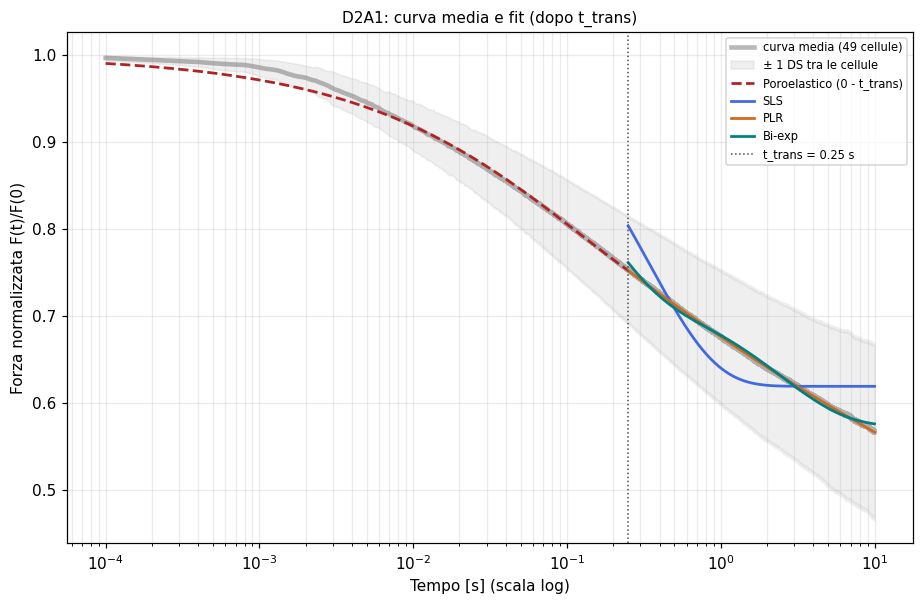

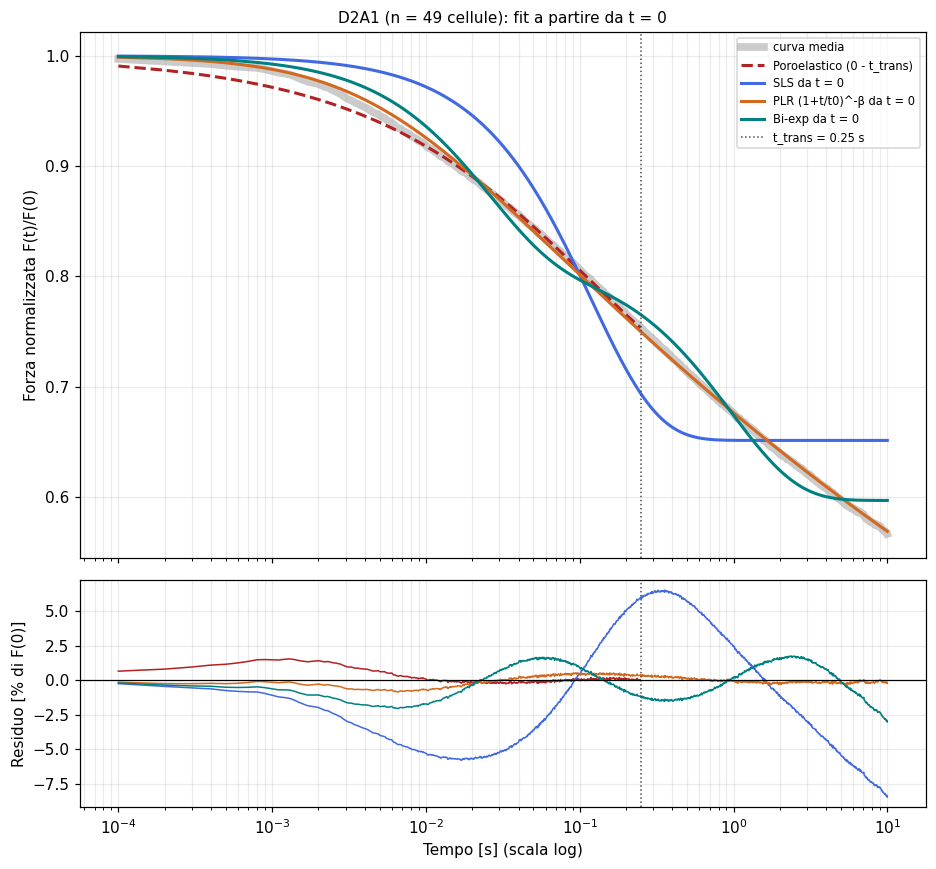

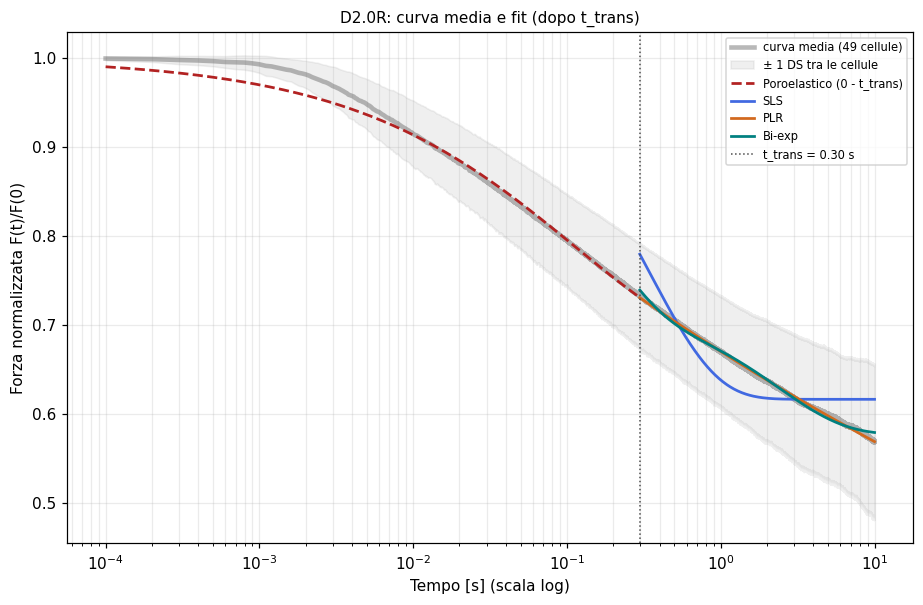

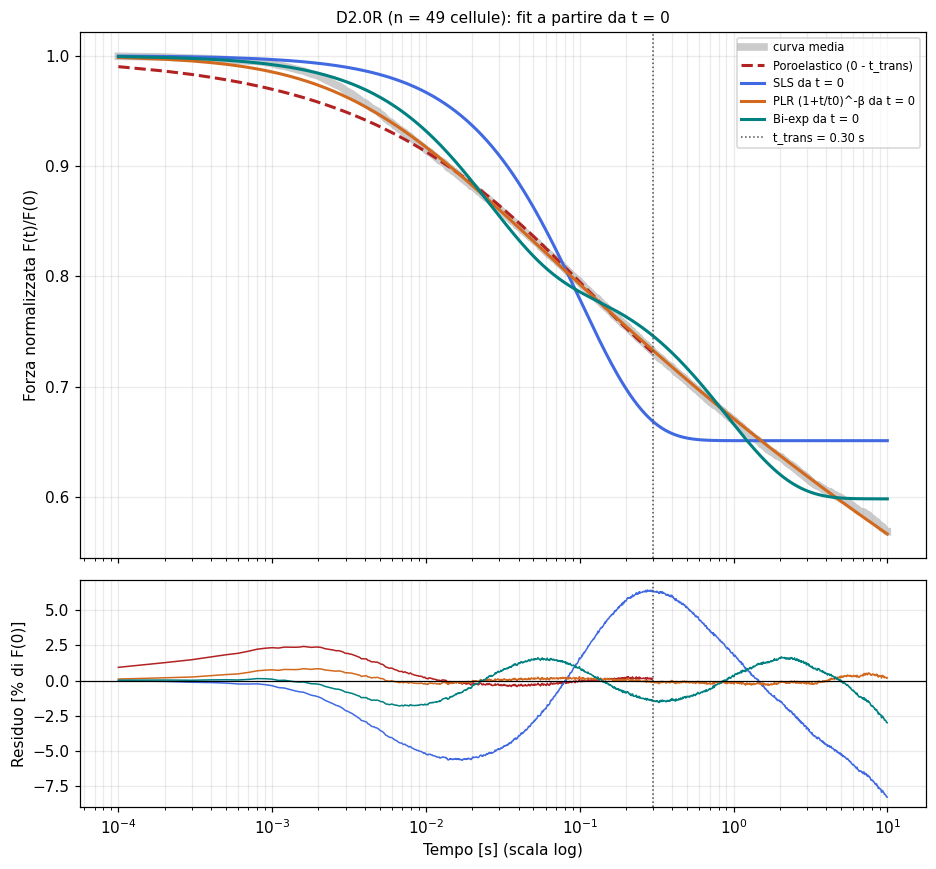

SR - fit sulla curva media di ciascuna linea:


,linea,n_cellule,F_0.1s,F_1s,F_relax,rilassamento_pct,SLS_F_inf,SLS_tau_s,PLR_beta,PLR_t0_s,BI_F_inf,BI_w,BI_tau1_s,BI_tau2_s,PORO_tau_p_s,t_trans_s
0,D2A1,49,0.8059,0.6757,0.5478,45.2230,0.6190,0.3456,0.0770,0.0062,0.5730,0.6329,0.1426,2.4680,0.1195,0.2500
1,D2.0R,49,0.7946,0.6697,0.5548,44.5209,0.6163,0.3479,0.0712,0.0036,0.5768,0.6641,0.1464,2.3931,0.1122,0.2975



Criteri di esclusione: {'fd_r2_min': 0.9, 'fd_betaE_at_bound': True, 'fd_max_rapporto_hertz_E0': 10.0, 'sr_F_relax_fisico': False, 'sr_r2_min': 0.9, 'sr_beta_at_bound': True}
Tenute dopo i criteri (dettaglio in esclusi_murine.csv):


,,D2A1,D2.0R
0,FD: curve,153 su 155,143 su 155
1,FD: cellule,50 su 50,49 su 50
2,SR: cellule,49 su 49,49 su 50



Riassunto forza-indentazione (media ± DS tra le cellule; p del test di Mann-Whitney sulle cellule):


,grandezza,D2A1,D2.0R,p (Mann-Whitney)
0,Ting PLR: E0 [Pa],722 ± 274 (n=50),1.24e+03 ± 573 (n=49),2.2e-06
1,Ting PLR: βE,0.0651 ± 0.0267 (n=50),0.0828 ± 0.0256 (n=49),0.000539
2,Hertz: E [Pa],713 ± 219 (n=50),1.22e+03 ± 539 (n=49),2.27e-07
3,Ting PLR: E0 corretto spessore [Pa],422 ± 166 (n=50),776 ± 390 (n=49),1.61e-06
4,Hertz: E corretto spessore [Pa],416 ± 129 (n=50),763 ± 361 (n=49),1.34e-07
5,Ting PLR: E0 corretto (coeff. Garcia) [Pa],399 ± 158 (n=50),743 ± 379 (n=49),1.5e-06
6,fattore di correzione (Dimitriadis),1.72 ± 0.064 (n=50),1.63 ± 0.108 (n=49),7.14e-06
7,indentazione massima [µm],0.865 ± 0.107 (n=50),0.725 ± 0.171 (n=49),4.64e-06



Riassunto stress-relaxation (media ± DS tra le cellule; p del test di Mann-Whitney sulle cellule):


,grandezza,D2A1,D2.0R,p (Mann-Whitney)
0,"forza a 0,1 s (F/F0)",0.806 ± 0.0512 (n=49),0.795 ± 0.0523 (n=49),0.17
1,forza a 1 s (F/F0),0.676 ± 0.0777 (n=49),0.67 ± 0.0628 (n=49),0.323
2,forza residua F_relax (F/F0),0.548 ± 0.103 (n=49),0.555 ± 0.0831 (n=49),0.579
3,rilassamento ΔF [%],45.2 ± 10.3 (n=49),44.5 ± 8.31 (n=49),0.579
4,SLS: F∞,0.606 ± 0.0923 (n=49),0.605 ± 0.0729 (n=49),0.293
5,SLS: τ [s],0.542 ± 0.207 (n=49),0.54 ± 0.209 (n=49),0.926
6,PLR: β,0.0804 ± 0.0386 (n=49),0.0724 ± 0.0304 (n=49),0.394
7,Bi-exp: F∞,0.51 ± 0.187 (n=49),0.488 ± 0.215 (n=49),0.629
8,Bi-exp: w,0.615 ± 0.123 (n=49),0.604 ± 0.117 (n=49),0.804
9,Bi-exp: τ1 [s],0.218 ± 0.114 (n=49),0.196 ± 0.135 (n=49),0.247


Figura per la tesi salvata: fig_tesi_box_murine.pdf
Figura per la tesi salvata: fig_tesi_FD_media_murine.pdf
Figura per la tesi salvata: fig_tesi_SR_media_murine.pdf
Figura per la tesi salvata: fig_tesi_SR_media_murine_lineare.pdf

Tabelle e report salvati in: /Users/furbetta/Desktop/PyFMlab_DyNaMo/PyFMGUI_DyNaMo/aggregated/per_cellula_murine_chiusura_contatto


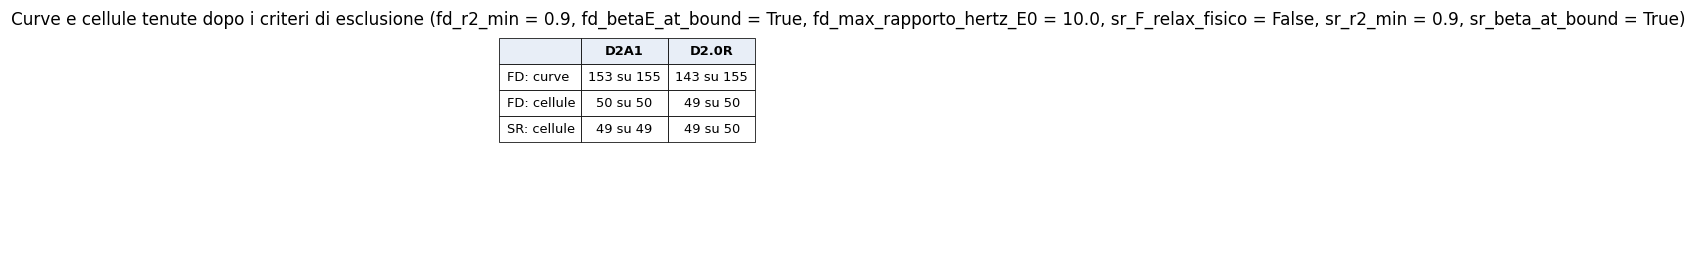

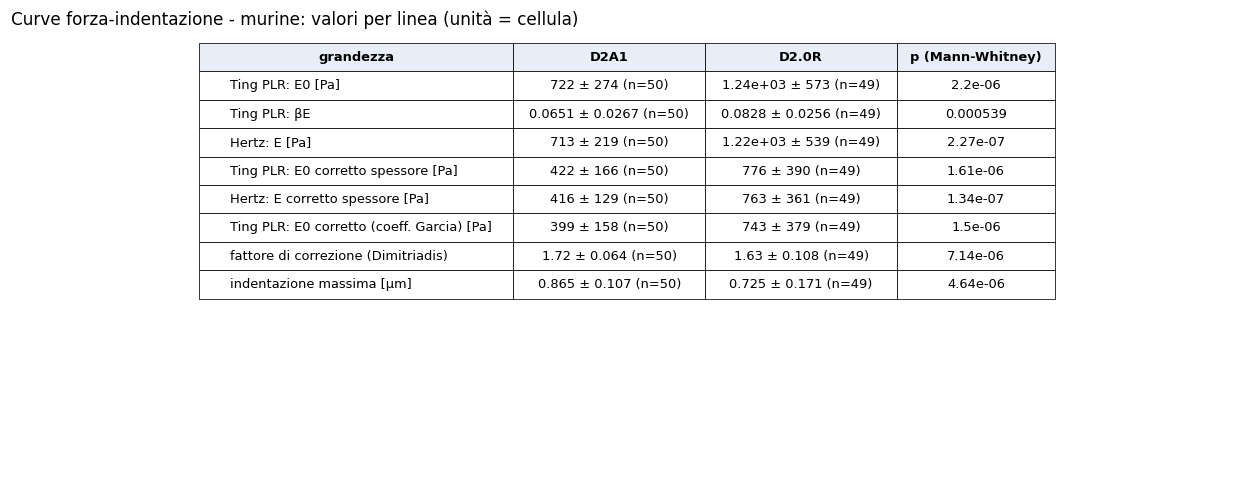

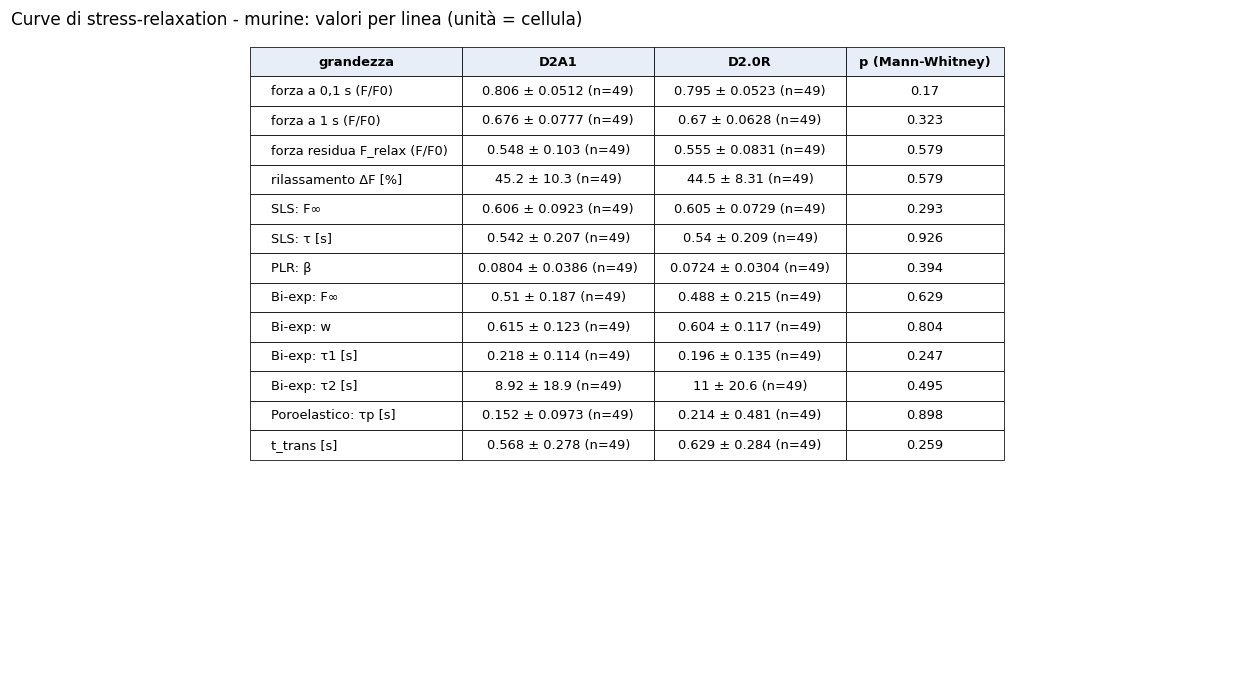

In [28]:
# 4. Analisi completa: FD (Ting) e SR, tabelle per cellula, medie per linea, test
risultati = apc.run_full_analysis(
    LINEE,
    SISTEMA,
    OUTPUT_DIR,
    run_fd=ESEGUI_FD,
    run_sr=ESEGUI_SR,
    criteri=CRITERI,
    ting_options=OPZIONI_TING,
    altezze_um=ALTEZZE_UM,
)